# Painel de séries: várias séries no mesmo experimento

Com um painel, as candidatas são comparadas em **todas** as séries ao mesmo tempo:

1. Cada série tem seu próprio **teste selado**, suas origens de validação e sua escala de MASE.
2. O **ranking** usa a melhor configuração de cada estrutura **em cada série** e tira a média dos postos entre as séries (convenção v1, ADR-0004).
3. A **seleção incremental** junta as unidades `série:dobra` de todas as séries: ganho mediano e taxa de vitórias são calculados sobre o conjunto.
4. A **finalização** reajusta cada série com a configuração escolhida para ela e devolve um `PanelForecaster`.

Um híbrido que ajuda muito em uma série e atrapalha em outra pode ser rejeitado no conjunto. Isso é intencional: a decisão vale para o painel.

In [1]:
import autohybts

print("AutoHybTS", autohybts.__version__)

AutoHybTS 0.0.1


## 1. Montar o painel

Três formas equivalentes de entrada: um dicionário `{id: pd.Series}`, um `PanelFrame` ou uma tabela longa com as colunas nomeadas explicitamente.

In [2]:
from autohybts import AutoHybridExperiment, PanelFrame
from autohybts.datasets import get_data

series = {
    "loja_a": get_data("synthetic_daily", n=400, seed=1),
    "loja_b": get_data("synthetic_daily", n=400, seed=2, phi=0.2),
    "loja_c": get_data("white_noise_daily", n=400, seed=3),
}
panel = PanelFrame.from_dict(series)
long = panel.to_long()
long.head()

,series_id,timestamp,value
0,loja_a,2024-01-01,50.000000
1,loja_a,2024-01-02,53.197113
2,loja_a,2024-01-03,53.890354
3,loja_a,2024-01-04,50.722393
4,loja_a,2024-01-05,49.255224


## 2. Experimento

A mesma chamada de uma série única. Para a tabela longa, informe `series_col`, `date_col` e `target`.

In [3]:
exp = AutoHybridExperiment(
    fh=14,
    session_id=42,
    fold=3,
    base_models=["naive", "seasonal_naive", "linear", "knn"],
    correctors=["linear"],
    residual_windows=[7],
).fit(long, series_col="series_id", date_col="timestamp", target="value")
exp.splits.head(8)

layer train_start     origin first_target last_target  \
series_id fold_id                                                            
loja_a    search-0  search  2024-01-01 2024-10-28   2024-10-29  2024-11-11   
          search-1  search  2024-01-01 2024-11-11   2024-11-12  2024-11-25   
          search-2  search  2024-01-01 2024-11-25   2024-11-26  2024-12-09   
          select-0  select  2024-01-01 2024-12-09   2024-12-10  2024-12-23   
          select-1  select  2024-01-01 2024-12-23   2024-12-24  2025-01-06   
          select-2  select  2024-01-01 2025-01-06   2025-01-07  2025-01-20   
loja_b    search-0  search  2024-01-01 2024-10-28   2024-10-29  2024-11-11   
          search-1  search  2024-01-01 2024-11-11   2024-11-12  2024-11-25   

                    n_train  horizon  
series_id fold_id                     
loja_a    search-0      302       14  
          search-1      316       14  
          search-2      330       14  
          select-0      344       14  
          select-1      358       14  
          select-2      372       14  
loja_b    search-0      302       14  
          search-1      316       14

In [4]:
exp.data_profile()

,loja_a,loja_b,loja_c
série,loja_a,loja_b,loja_c
início,2024-01-01 00:00:00,2024-01-01 00:00:00,2024-01-01 00:00:00
fim,2025-01-20 00:00:00,2025-01-20 00:00:00,2025-01-20 00:00:00
observações,386,386,386
frequência,D,D,D
faltantes,0,0,0
datas duplicadas,0,0,0
média,55.484794,55.726255,50.031984
desvio-padrão,4.0998,3.953511,1.012719
mínimo,45.566595,46.758314,46.941619


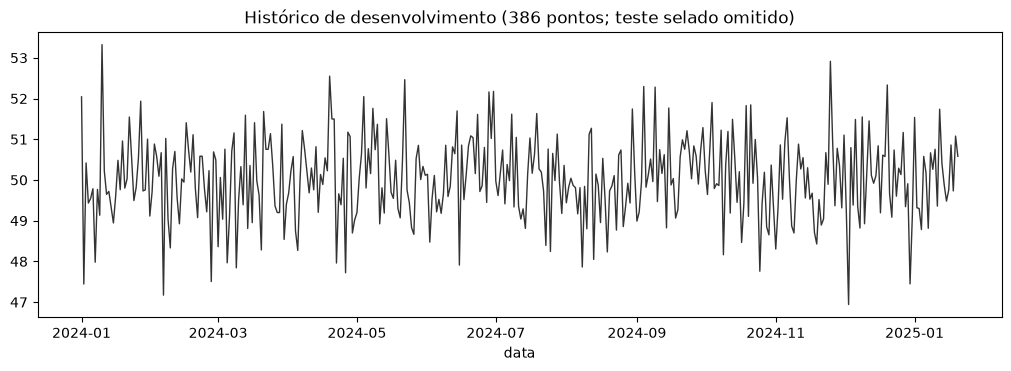

In [5]:
exp.plot_data("series", series_id="loja_c")

## 3. Busca, ranking entre séries e seleção

In [6]:
result = exp.compare_models()
result.leaderboard.head(10)

,name,model,family,strategy,base,corrector,residual_source,window,alpha,mean_rank,...,MAE,RMSE,sMAPE,coverage,n_units,n_failed,n_skipped,fit_seconds,predict_seconds,is_champion
candidate_id,,,,,,,,,,,,,,,,,,,,,
e9e747a9648ad8d377f20122dce611a43dd3bf85a64c950a8e1ef246ebc032b4,linear,linear(lags=7),linear,standalone,linear,NaN,NaN,NaN,NaN,1.0,...,1.187120,1.400000,0.020918,1.0,9,0,0,4.420429,0.082269,False
c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1fd3722f7c6ed592f9b,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,0.5,2.0,...,1.197439,1.402873,0.021120,1.0,9,0,0,1.827313,0.093149,True
b678627c69f0bc5eb419617a2119103a8a5340ac96c0551898c62a1d76dc0179,linear-linear,"linear(lags=7) + linear [w=7, alpha=1.0, histo...",residual,residual_additive,linear,linear,historical_oof_1step,7.0,1.0,3.0,...,1.221169,1.431294,0.021547,1.0,9,0,0,1.980473,0.124311,False
70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d09d35dac0019c7ef37,knn,knn(lags=7),kernel,standalone,knn,NaN,NaN,NaN,NaN,4.0,...,1.270992,1.540000,0.022512,1.0,9,0,0,0.118970,0.258884,False
773d3b8c8d625571d4d4b4f4aa234d9f88b9b7fc0ceb3101c126e49e100378fc,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,0.5,5.0,...,1.313242,1.537258,0.023246,1.0,9,0,0,0.852773,0.061263,False
507265ea41efe47e82119ba51bc162c1cd983e9fd72f0a1b25e7ca1c8d95b229,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_1step,7.0,1.0,6.0,...,1.339927,1.581616,0.023777,1.0,9,0,0,0.842571,0.051826,False
d90528888825a4459816afbcf249ff909747924f0a2bbaa6e09d027e31342238,seasonal_naive,seasonal_naive(season_length=7),statistical,standalone,seasonal_naive,NaN,NaN,NaN,NaN,7.0,...,1.342596,1.570915,0.023741,1.0,9,0,0,0.000185,0.000502,False
2948929df89de24864d7dc328f6eaad73372295f0ac9c1a0b90ee60e1d5a5bf3,linear-linear,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",residual,residual_additive,linear,linear,historical_oof_multistep,7.0,0.5,8.0,...,1.520219,1.761318,0.026350,1.0,9,0,0,1.129011,0.103967,False
bbd8aa955229e78f79ee95ec40b350010922f578702fd6a464ea2ea729023f34,seasonal_naive-linear,"seasonal_naive(season_length=7) + linear [w=7,...",residual,residual_additive,seasonal_naive,linear,historical_oof_multistep,7.0,0.5,9.0,...,1.591184,1.894029,0.028089,1.0,9,0,0,0.490900,0.040073,False


Histórico de decisões: `median_gain` e `win_rate` vêm das unidades de **todas** as séries (`n_units`).

In [7]:
result.decisions

,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate,variability_status,variability_value,p_value,challenger_coverage,challenger_label,champion_before_id,challenger_id
0,statistical,linear,seasonal_naive,False,"(median_gain_below_threshold, win_rate_below_t...",-0.318080,0.111111,not_applicable,NaN,None,1.0,seasonal_naive(season_length=7),e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,d90528888825a4459816afbcf249ff909747924f0a2bba...
1,kernel,linear,knn,False,"(median_gain_below_threshold, win_rate_below_t...",-0.299249,0.111111,not_applicable,NaN,None,1.0,knn(lags=7),e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,70ad174e1cc49eb256646399fb3e4b7d9df82f14f2978d...
2,residual,linear,linear-linear,True,"(accepted,)",0.013144,0.777778,passed,0.316343,None,1.0,"linear(lags=7) + linear [w=7, alpha=0.5, histo...",e9e747a9648ad8d377f20122dce611a43dd3bf85a64c95...,c4821c0a39e39a26ca17be31d8298f1ebcaed90d98e0a1...


Configuração da estrutura campeã em cada série (a melhor configuração por série):

In [8]:
{sid: spec.label for sid, spec in result.selection.champion_per_series.items()}

{'loja_a': 'linear(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]',
 'loja_b': 'linear(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]',
 'loja_c': 'linear(lags=7) + linear [w=7, alpha=0.5, historical_oof_multistep]'}

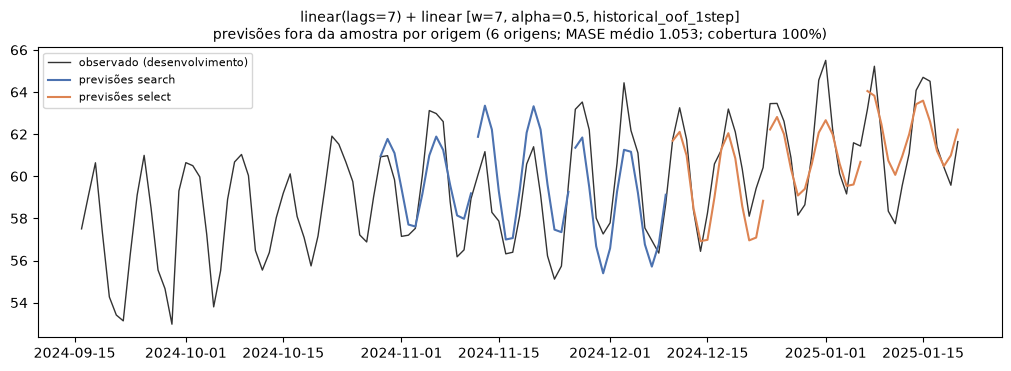

In [9]:
exp.plot_model(result.best, "cv_forecasts", series_id="loja_a")

## 4. Validação cruzada temporal no painel

As dobras são criadas por série; as unidades da comparação são `série:dobra`.

In [10]:
cv = exp.cross_validate(models=["naive", "seasonal_naive", "linear", result.best], folds=4)
cv.summary

,mean,std,median,n_valid,n_units,mean_rank
model,,,,,,
linear-linear,0.879899,0.208940,0.850235,12,12,1.583333
linear,0.888316,0.221479,0.884719,12,12,1.666667
seasonal_naive,1.105422,0.249782,1.055381,12,12,3.000000
naive,1.656280,0.569859,1.631295,12,12,3.750000


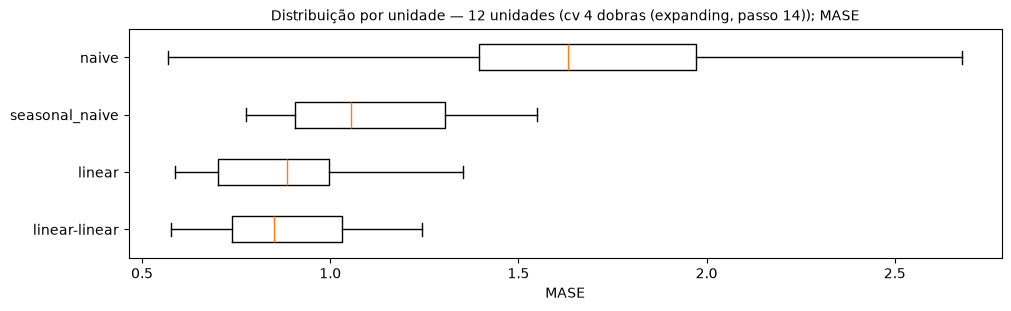

In [11]:
cv.plot("boxplot")

## 5. Finalizar, prever e avaliar no teste selado

Cada série é reajustada com a sua configuração até o fim do seu histórico de desenvolvimento. A avaliação externa traz uma linha por série e a média; ela só pode ser feita uma vez por modelo.

In [12]:
model = exp.finalize_model(result.best)
model

PanelForecaster('linear(lags=7) + linear [w=7, alpha=0.5, historical_oof_1step]', 3 séries)

In [13]:
exp.predict_model(model).predictions.groupby("series_id").head(3)

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-01-21,loja_a,2025-01-20,1,63.830350
2025-01-22,loja_a,2025-01-20,2,64.887077
2025-01-23,loja_a,2025-01-20,3,64.196555
2025-01-21,loja_b,2025-01-20,1,63.639950
2025-01-22,loja_b,2025-01-20,2,63.943532
2025-01-23,loja_b,2025-01-20,3,62.722960
2025-01-21,loja_c,2025-01-20,1,49.950590
2025-01-22,loja_c,2025-01-20,2,50.064736
2025-01-23,loja_c,2025-01-20,3,49.910459


In [14]:
exp.evaluate_external(model).metrics

MASE  \
model                                              series_id             
linear(lags=7) + linear [w=7, alpha=0.5, histor... loja_a     0.946954   
                                                   loja_b     0.917803   
                                                   loja_c     0.629653   
                                                   média      0.831470   

                                                                   MAE  \
model                                              series_id             
linear(lags=7) + linear [w=7, alpha=0.5, histor... loja_a     1.144450   
                                                   loja_b     1.087111   
                                                   loja_c     0.697431   
                                                   média      0.976331   

                                                                  RMSE  \
model                                              series_id             
linear(lags=7) + linear [w=7, alpha=0.5, histor... loja_a     1.539107   
                                                   loja_b     1.243789   
                                                   loja_c     0.883545   
                                                   média      1.222147   

                                                                 sMAPE  
model                                              series_id            
linear(lags=7) + linear [w=7, alpha=0.5, histor... loja_a     0.018665  
                                                   loja_b     0.017570  
                                                   loja_c     0.013947  
                                                   média      0.016728

## 6. Salvar e carregar

In [15]:
import tempfile

from autohybts import load_model, save_model

with tempfile.TemporaryDirectory() as folder:
    path = save_model(model, folder)
    loaded = load_model(path, trusted=True)
loaded.predict(3)

,series_id,origin,horizon,y_pred
timestamp,,,,
2025-01-21,loja_a,2025-01-20,1,63.830350
2025-01-22,loja_a,2025-01-20,2,64.887077
2025-01-23,loja_a,2025-01-20,3,64.196555
2025-01-21,loja_b,2025-01-20,1,63.639950
2025-01-22,loja_b,2025-01-20,2,63.943532
2025-01-23,loja_b,2025-01-20,3,62.722960
2025-01-21,loja_c,2025-01-20,1,49.950590
2025-01-22,loja_c,2025-01-20,2,50.064736
2025-01-23,loja_c,2025-01-20,3,49.910459
